# 1. Разведочный анализ CIFAR-10

Цель: понять объём, баланс классов, статистику пикселей и ограничения датасета для DDPM. Источник — [University of Toronto](https://www.cs.toronto.edu/~kriz/cifar.html), версия Python. Код выполняется последовательно сверху вниз. Нужны `numpy` и `matplotlib`. Данные: `CourseWork/data/cifar-10-python.tar.gz`. Анализируем только изображения, **не обучаем модель**.

## 1.1. Подготовка путей и проверка архива
Не используем `CIFAR-master.zip`: там нет изображений. Проверка MD5 защищает от неполной загрузки.

In [1]:
from pathlib import Path
from IPython.display import display
import hashlib
import pickle
import tarfile
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / 'data').exists(): root = root.parent
data_path = root / 'data' / 'cifar-10-python.tar.gz'
assert data_path.exists(), f'Скачайте CIFAR-10 Python version: {data_path}'
print('Размер архива:', data_path.stat().st_size, 'байт')

Размер архива: 170498071 байт


In [2]:
expected_size = 170_498_071
expected_md5 = 'c58f30108f718f92721af3b95e74349a'
assert data_path.stat().st_size == expected_size, 'Архив скачан не полностью'
md5 = hashlib.md5()
with data_path.open('rb') as file:
    for block in iter(lambda: file.read(1024 * 1024), b''):
        md5.update(block)
assert md5.hexdigest() == expected_md5, 'Контрольная сумма CIFAR-10 не совпала'
print('MD5 подтверждён:', md5.hexdigest())

MD5 подтверждён: c58f30108f718f92721af3b95e74349a


## 1.2. Загрузка изображений и меток
В архиве пять обучающих частей и одна тестовая. Порядок пикселей: сначала вся плоскость R, потом G и B.

In [3]:
with tarfile.open(data_path, 'r:gz') as archive:
    train_batches = []
    for number in range(1, 6):
        with archive.extractfile(f'cifar-10-batches-py/data_batch_{number}') as file:
            train_batches.append(pickle.load(file, encoding='bytes'))
    with archive.extractfile('cifar-10-batches-py/test_batch') as file:
        test_batch = pickle.load(file, encoding='bytes')
    with archive.extractfile('cifar-10-batches-py/batches.meta') as file:
        meta = pickle.load(file, encoding='bytes')

class_names = [name.decode('utf-8') for name in meta[b'label_names']]
train_flat = np.concatenate([batch[b'data'] for batch in train_batches])
train_labels = np.concatenate([batch[b'labels'] for batch in train_batches])
test_flat = test_batch[b'data']
test_labels = np.array(test_batch[b'labels'])
print('Official train:', train_flat.shape, 'test:', test_flat.shape)
print('Классы:', class_names)

Official train: (50000, 3072) test: (10000, 3072)
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [4]:
train_images = train_flat.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
test_images = test_flat.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
assert train_images.shape == (50_000, 32, 32, 3)
assert test_images.shape == (10_000, 32, 32, 3)
print('Тип:', train_images.dtype, 'диапазон:', int(train_images.min()), int(train_images.max()))

Тип: uint8 диапазон: 0 255


## 1.3. Примеры изображений
По пять случайных изображений каждого класса из обучающей части.

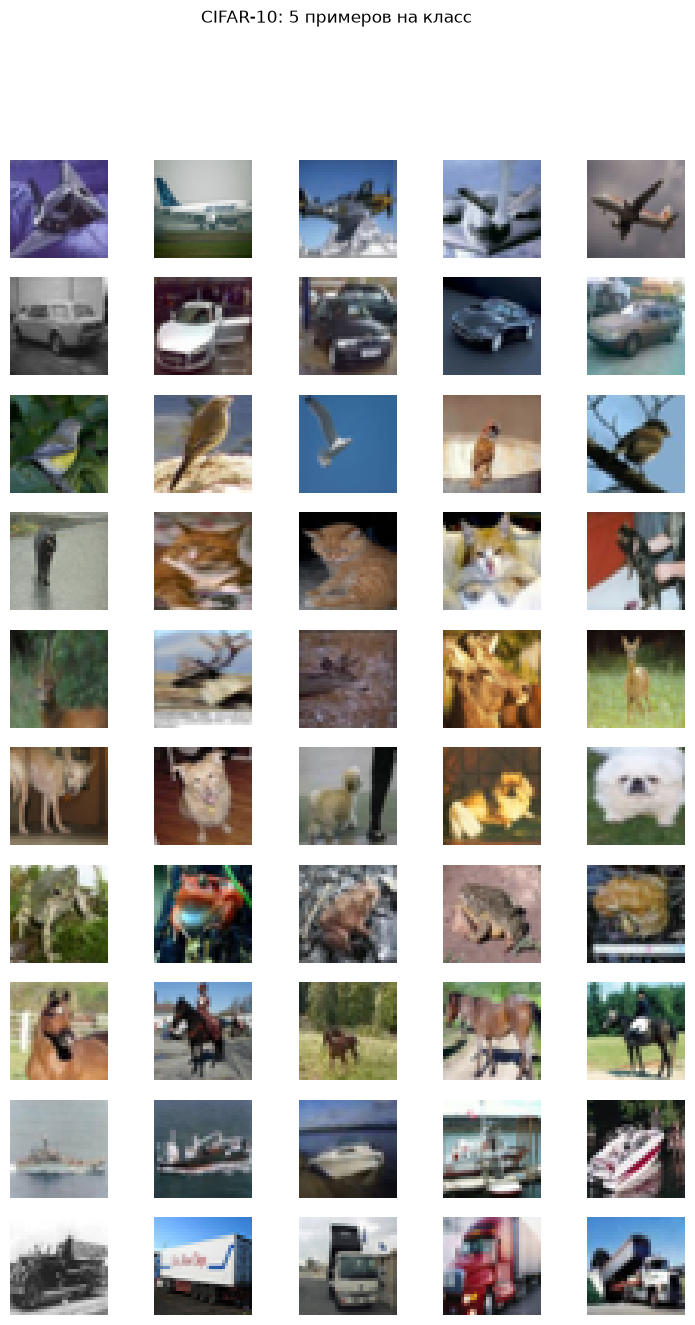

In [5]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(10, 5, figsize=(9, 15))
for cls in range(10):
    ids = rng.choice(np.flatnonzero(train_labels == cls), 5, replace=False)
    for ax, idx in zip(axes[cls], ids):
        ax.imshow(train_images[idx]); ax.axis('off')
    axes[cls, 0].set_ylabel(class_names[cls], rotation=0, ha='right', va='center', labelpad=35)
fig.suptitle('CIFAR-10: 5 примеров на класс')
display(fig)
plt.close(fig)

## 1.4. Train / validation / test
Отделяем 500 изображений каждого класса в validation. Официальную test-часть не используем для подбора модели. Используем фиксированный seed=42 для воспроизводимости.

In [6]:
rng = np.random.default_rng(42)
val_idx = np.sort(np.concatenate([
    rng.choice(np.flatnonzero(train_labels == cls), 500, replace=False)
    for cls in range(10)
]))
train_idx = np.setdiff1d(np.arange(len(train_images)), val_idx)
counts = {
    'train': np.bincount(train_labels[train_idx], minlength=10).tolist(),
    'val': np.bincount(train_labels[val_idx], minlength=10).tolist(),
    'test': np.bincount(test_labels, minlength=10).tolist(),
}
print('Размеры:', {k: sum(v) for k, v in counts.items()})
print('Объектов на класс:', counts)

Размеры: {'train': 45000, 'val': 5000, 'test': 10000}
Объектов на класс: {'train': [4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500], 'val': [500, 500, 500, 500, 500, 500, 500, 500, 500, 500], 'test': [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]}


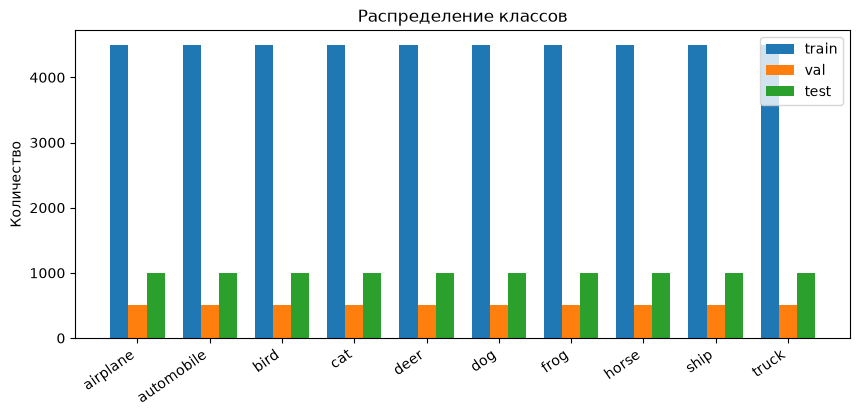

In [7]:
x = np.arange(10)
fig, ax = plt.subplots(figsize=(10, 4))
for offset, split in [(-.25, 'train'), (0, 'val'), (.25, 'test')]:
    ax.bar(x + offset, counts[split], width=.25, label=split)
ax.set_xticks(x, class_names, rotation=35, ha='right')
ax.set_ylabel('Количество'); ax.set_title('Распределение классов'); ax.legend()
display(fig)
plt.close(fig)

## 1.5. Цветовые характеристики и нормализация
Считаем значения **только по train после разбиения**. Для DDPM впоследствии удобно преобразование `x / 127.5 - 1`, то есть в диапазон `[-1, 1]`. Не подменяем им исходные статистики.

In [8]:
pixels = train_images[train_idx]
means = pixels.mean(axis=(0, 1, 2)) / 255
stds = pixels.std(axis=(0, 1, 2)) / 255
print('Среднее RGB [0,1]:', np.round(means, 4))
print('Ст. отклонение RGB:', np.round(stds, 4))

Среднее RGB [0,1]: [0.4913 0.4821 0.4465]
Ст. отклонение RGB: [0.2472 0.2436 0.2617]


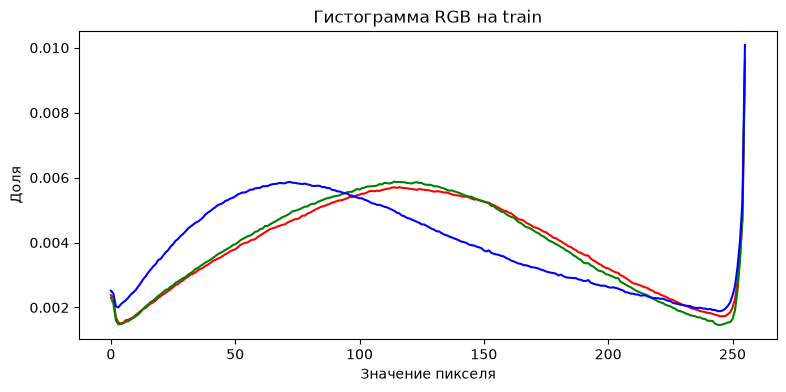

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
for channel, color in enumerate('rgb'):
    hist = np.bincount(pixels[:, :, :, channel].ravel(), minlength=256)
    ax.plot(np.arange(256), hist / hist.sum(), color=color, label='RGB'[channel])
ax.set(xlabel='Значение пикселя', ylabel='Доля', title='Гистограмма RGB на train')
display(fig)
plt.close(fig)

## 1.6. Яркость, контраст и необычные изображения
Темнота или яркость сами по себе не повод удалять объект из генеративного датасета.

In [10]:
brightness = pixels.mean(axis=(1, 2, 3)) / 255
contrast = pixels.std(axis=(1, 2, 3)) / 255
quantiles = [0, .01, .5, .99, 1]
print('Квантили яркости:', np.round(np.quantile(brightness, quantiles), 4))
print('Квантили контраста:', np.round(np.quantile(contrast, quantiles), 4))

Квантили яркости: [0.0309 0.196  0.4661 0.8041 0.9894]
Квантили контраста: [0.0399 0.0945 0.2095 0.3431 0.4509]


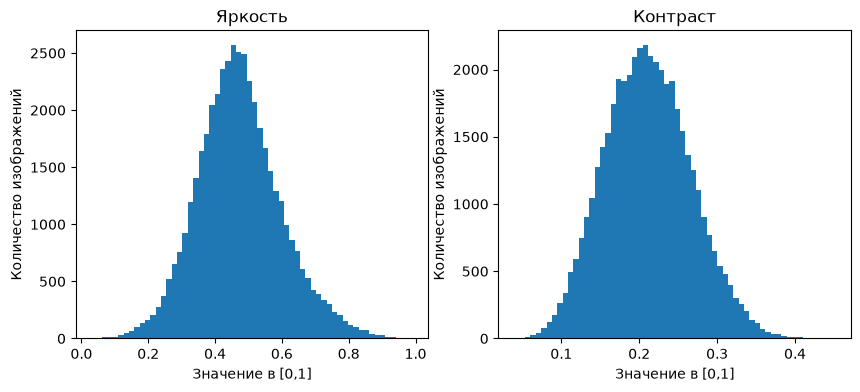

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, values, title in zip(axes, (brightness, contrast), ('Яркость', 'Контраст')):
    ax.hist(values, bins=60)
    ax.set(xlabel='Значение в [0,1]', ylabel='Количество изображений', title=title)
display(fig)
plt.close(fig)

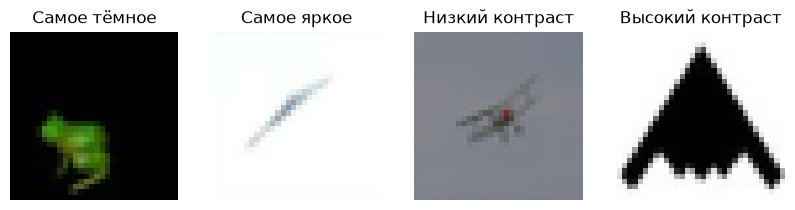

In [12]:
extreme = [brightness.argmin(), brightness.argmax(), contrast.argmin(), contrast.argmax()]
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, idx, title in zip(axes, extreme, ('Самое тёмное', 'Самое яркое', 'Низкий контраст', 'Высокий контраст')):
    ax.imshow(pixels[idx]); ax.set_title(title); ax.axis('off')
display(fig)
plt.close(fig)

## 1.7. Проверка точных повторов
Сравниваем байты изображений независимо от меток. Это **не** поиск почти одинаковых изображений.

In [13]:
train_hashes = [hashlib.sha256(row.tobytes()).digest() for row in train_flat]
test_hashes = [hashlib.sha256(row.tobytes()).digest() for row in test_flat]
train_duplicates = len(train_hashes) - len(set(train_hashes))
test_duplicates = len(test_hashes) - len(set(test_hashes))
train_test_overlap = len(set(train_hashes) & set(test_hashes))
print('Повторы official train:', train_duplicates)
print('Повторы official test:', test_duplicates)
print('Совпадения train/test:', train_test_overlap)

Повторы official train: 0
Повторы official test: 0
Совпадения train/test: 0


## 1.8. Иллюстрация прямой диффузии
Одна фотография последовательно зашумляется согласно предполагаемому линейному расписанию из 1000 шагов. Это **не** работа обученной модели.

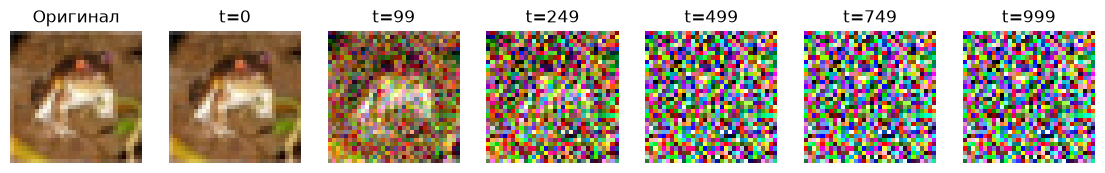

In [14]:
betas = np.linspace(1e-4, .02, 1000)
alpha_bar = np.cumprod(1 - betas)
x0 = pixels[0].astype(np.float32) / 127.5 - 1
noise = np.random.default_rng(42).standard_normal(x0.shape)
steps = [0, 99, 249, 499, 749, 999]
fig, axes = plt.subplots(1, 7, figsize=(14, 2.7))
axes[0].imshow((x0 + 1) / 2); axes[0].set_title('Оригинал'); axes[0].axis('off')
for ax, t in zip(axes[1:], steps):
    xt = np.sqrt(alpha_bar[t]) * x0 + np.sqrt(1 - alpha_bar[t]) * noise
    ax.imshow(np.clip((xt + 1) / 2, 0, 1)); ax.set_title(f't={t}'); ax.axis('off')
display(fig)
plt.close(fig)

## 1.9. Сводка результатов

In [15]:
summary = {
    'dataset': 'CIFAR-10', 'source': 'https://www.cs.toronto.edu/~kriz/cifar.html',
    'shape': [32, 32, 3], 'dtype': str(train_images.dtype),
    'pixel_range': [int(train_images.min()), int(train_images.max())],
    'class_names': class_names, 'counts_by_class': counts,
    'train_channel_mean_0_1': means.tolist(), 'train_channel_std_0_1': stds.tolist(),
    'train_brightness_quantiles_0_1': np.quantile(brightness, quantiles).tolist(),
    'train_contrast_quantiles_0_1': np.quantile(contrast, quantiles).tolist(),
    'exact_duplicates_within_official_train': train_duplicates,
    'exact_duplicates_within_test': test_duplicates,
    'exact_train_test_overlap': train_test_overlap, 'seed': 42,
}
display(summary)

{'dataset': 'CIFAR-10',
 'source': 'https://www.cs.toronto.edu/~kriz/cifar.html',
 'shape': [32, 32, 3],
 'dtype': 'uint8',
 'pixel_range': [0, 255],
 'class_names': ['airplane',
  'automobile',
  'bird',
  'cat',
  'deer',
  'dog',
  'frog',
  'horse',
  'ship',
  'truck'],
 'counts_by_class': {'train': [4500,
   4500,
   4500,
   4500,
   4500,
   4500,
   4500,
   4500,
   4500,
   4500],
  'val': [500, 500, 500, 500, 500, 500, 500, 500, 500, 500],
  'test': [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]},
 'train_channel_mean_0_1': [0.4912593319376362,
  0.48206658794594226,
  0.44652213192742374],
 'train_channel_std_0_1': [0.24715248464275666,
  0.24360179150665678,
  0.2616557515372759],
 'train_brightness_quantiles_0_1': [0.030916819852941178,
  0.19596835426879086,
  0.4660603043300654,
  0.8040761335784314,
  0.9893995098039216],
 'train_contrast_quantiles_0_1': [0.0398855132164107,
  0.09449359217625065,
  0.20949983268764377,
  0.343109250126131,
  0.450948173

### Вывод
CIFAR-10 — цветной и сбалансированный набор в 32×32. Для выбора между тремя наборами нужны результаты следующих двух EDA. 